In [2]:
import os

print("Current folder:", os.getcwd())
print("Files:", os.listdir())

Current folder: /home/evas-2026/spark_easter_2026
Files: ['models', 'stream_folder', 'stream_sample_2', 'stream_sample', 'data', 'Assignment', 'stream_output', 'TUMUHIMBISE EVAS', 'venv', '01_NYC_Taxi_Data_Exploration.ipynb', 'Untitled1.ipynb', 'taxi_zone_lookup.csv', 'Week 1 Taxi Records.ipynb', 'transactions_by_hour.png', 'stream_checkpoint', 'lab2.py', 'yellow_tripdata_2025-01.parquet', '.ipynb_checkpoints', 'practice', 'mobile_money_transaction_dataset.csv', 'Untitled.ipynb', 'mobile_money_roc_curve.png', 'momo.ipynb', 'Projects']


In [3]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("NYC Taxi Big Data Analytics") \
    .master("local[2]") \
    .config("spark.driver.memory", "3g") \
    .config("spark.sql.shuffle.partitions", "8") \
    .getOrCreate()

print("PySpark initialized successfully!")
print("Spark Version:", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/03 09:45:00 WARN Utils: Your hostname, DESKTOP-FJIT3EI, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/03 09:45:00 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/evas-2026/spark_easter_2026/venv/lib/python3.14/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/03 09:45:11 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


PySpark initialized successfully!
Spark Version: 4.2.0


In [4]:
import os

print("Current directory:", os.getcwd())
print("Operating system:", os.name)

print("Dataset exists:",
      os.path.isfile("yellow_tripdata_2025-01.parquet"))

Current directory: /home/evas-2026/spark_easter_2026
Operating system: posix
Dataset exists: True


In [5]:
df = spark.read.parquet(
    "yellow_tripdata_2025-01.parquet"
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
df.printSchema()

df.show(5, truncate=False)

print("Total Taxi Trips:", df.count())

root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- cbd_congestion_fee: double (nullable = true)



+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|RatecodeID|store_and_fwd_flag|PULocationID|DOLocationID|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|Airport_fee|cbd_congestion_fee|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|1       |2025-01-01 00:18:38 |2025-01-01 00:26:59  |1              |1.6          |1         |N                 |229         |237 

In [7]:
#Count the total number of taxi trips
total_trips = df.count()

print("Total number of taxi trips:", total_trips)

Total number of taxi trips: 3475226


In [8]:
#Display the first 10 Records
df.show(10, truncate=False)

+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|RatecodeID|store_and_fwd_flag|PULocationID|DOLocationID|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|Airport_fee|cbd_congestion_fee|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|1       |2025-01-01 00:18:38 |2025-01-01 00:26:59  |1              |1.6          |1         |N                 |229         |237 

In [9]:
#Generate summary statitics
df.select(
    "trip_distance",
    "fare_amount",
    "tip_amount",
    "total_amount",
    "passenger_count"
).describe().show()

26/11/03 09:45:25 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
[Stage 9:=============================>                             (1 + 1) / 2]

+-------+------------------+------------------+------------------+------------------+------------------+
|summary|     trip_distance|       fare_amount|        tip_amount|      total_amount|   passenger_count|
+-------+------------------+------------------+------------------+------------------+------------------+
|  count|           3475226|           3475226|           3475226|           3475226|           2935077|
|   mean|5.8551261788432925|17.081802760456707| 2.959812786275976|25.611291697295062|1.2978589658806226|
| stddev|  564.601599634634| 463.4729178173049|3.7796811536124078| 463.6584784502283| 0.750750275480471|
|    min|               0.0|            -900.0|             -86.0|            -901.0|                 0|
|    max|         276423.57|         863372.12|             400.0|         863380.37|                 9|
+-------+------------------+------------------+------------------+------------------+------------------+



In [10]:
#calculate the average trip distance
from pyspark.sql.functions import avg

df.select(
    avg("trip_distance").alias("Average_Trip_Distance")
).show()

+---------------------+
|Average_Trip_Distance|
+---------------------+
|   5.8551261788432925|
+---------------------+



In [11]:
#Identify the busiest pickup hours
from pyspark.sql.functions import hour, col

df.groupBy(
    hour("tpep_pickup_datetime").alias("pickup_hour")
).count().orderBy(
    col("count").desc()
).show(24)

[Stage 15:>                                                         (0 + 2) / 2]

+-----------+------+
|pickup_hour| count|
+-----------+------+
|         18|267951|
|         17|253518|
|         19|221055|
|         16|217051|
|         15|213694|
|         21|205978|
|         14|202289|
|         20|195001|
|         13|186144|
|         22|182214|
|         12|175432|
|         11|160076|
|         10|148316|
|          9|142877|
|          8|141305|
|         23|136812|
|          7|102581|
|          0| 93417|
|          1| 64484|
|          6| 50026|
|          2| 43929|
|          3| 28492|
|          5| 22551|
|          4| 20033|
+-----------+------+



In [65]:
from pyspark.sql.functions import date_format, col

df.groupBy(
    date_format(
        "tpep_pickup_datetime", "EEEE"
    ).alias("pickup_day")
).count().orderBy(
    col("count").desc()
).show()

[Stage 184:============================>                            (1 + 1) / 2]

+----------+------+
|pickup_day| count|
+----------+------+
|  Thursday|614230|
|    Friday|586863|
| Wednesday|577375|
|  Saturday|476399|
|   Tuesday|453993|
|    Sunday|402594|
|    Monday|363772|
+----------+------+



In [12]:
#identify the top 10 pickup locations
df.groupBy("PULocationID") \
    .count() \
    .orderBy(col("count").desc()) \
    .show(10)

+------------+------+
|PULocationID| count|
+------------+------+
|         161|169977|
|         237|163703|
|         236|155647|
|         132|146137|
|         230|125829|
|         186|119131|
|         162|117930|
|         142|110585|
|         239| 96614|
|         163| 95906|
+------------+------+
only showing top 10 rows


In [13]:
#Total taxi records in January 2025 NYC Yellow Taxi Dataset
(df.count())

3475226

In [14]:
#Generate summary statistics
df.select(
    "trip_distance",
    "fare_amount",
    "tip_amount",
    "total_amount",
    "passenger_count"
).describe().show()


+-------+------------------+------------------+------------------+------------------+------------------+
|summary|     trip_distance|       fare_amount|        tip_amount|      total_amount|   passenger_count|
+-------+------------------+------------------+------------------+------------------+------------------+
|  count|           3475226|           3475226|           3475226|           3475226|           2935077|
|   mean|5.8551261788432925|17.081802760456707| 2.959812786275976|25.611291697295062|1.2978589658806226|
| stddev|  564.601599634634| 463.4729178173049|3.7796811536124078| 463.6584784502283| 0.750750275480471|
|    min|               0.0|            -900.0|             -86.0|            -901.0|                 0|
|    max|         276423.57|         863372.12|             400.0|         863380.37|                 9|
+-------+------------------+------------------+------------------+------------------+------------------+



In [15]:
from pyspark.sql.functions import hour, col

pickup_hours = df.groupBy(
    hour("tpep_pickup_datetime").alias("pickup_hour")
).count().orderBy(
    col("count").desc()
)

pickup_hours.show(24)

[Stage 27:=============================>                            (1 + 1) / 2]

+-----------+------+
|pickup_hour| count|
+-----------+------+
|         18|267951|
|         17|253518|
|         19|221055|
|         16|217051|
|         15|213694|
|         21|205978|
|         14|202289|
|         20|195001|
|         13|186144|
|         22|182214|
|         12|175432|
|         11|160076|
|         10|148316|
|          9|142877|
|          8|141305|
|         23|136812|
|          7|102581|
|          0| 93417|
|          1| 64484|
|          6| 50026|
|          2| 43929|
|          3| 28492|
|          5| 22551|
|          4| 20033|
+-----------+------+



/home/evas-2026/spark_easter_2026/venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/evas-2026/spark_easter_2026/venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


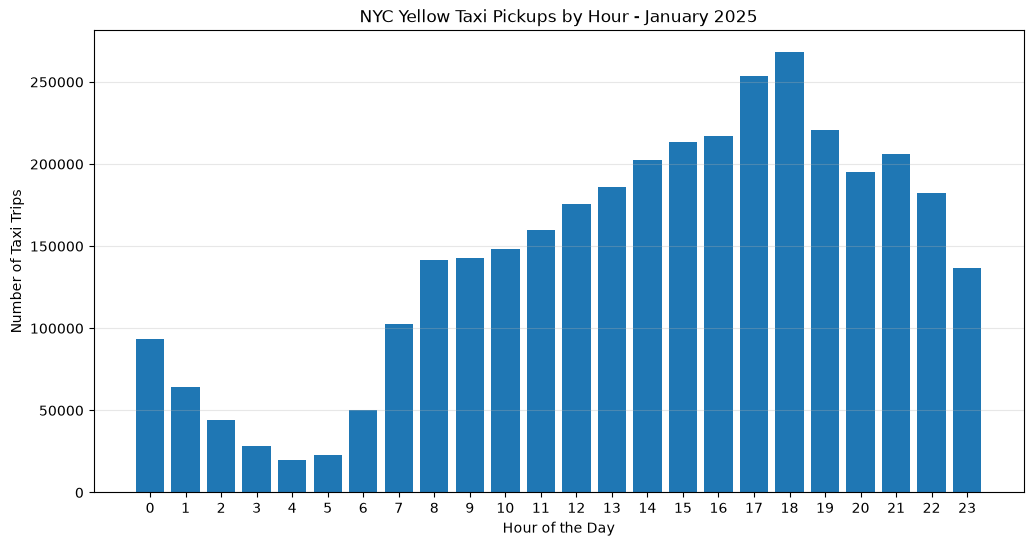

In [16]:
import matplotlib.pyplot as plt

hours_pd = pickup_hours.orderBy("pickup_hour").toPandas()

plt.figure(figsize=(12, 6))

plt.bar(
    hours_pd["pickup_hour"],
    hours_pd["count"]
)

plt.xlabel("Hour of the Day")
plt.ylabel("Number of Taxi Trips")
plt.title("NYC Yellow Taxi Pickups by Hour - January 2025")

plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)

plt.show()

In [17]:
#Analyze the top 10 busiest pickup locations/zones
from pyspark.sql.functions import col

top_pickup_zones = (
    df.groupBy("PULocationID")
      .count()
      .orderBy(col("count").desc())
      .limit(10)
)

top_pickup_zones.show()

+------------+------+
|PULocationID| count|
+------------+------+
|         161|169977|
|         237|163703|
|         236|155647|
|         132|146137|
|         230|125829|
|         186|119131|
|         162|117930|
|         142|110585|
|         239| 96614|
|         163| 95906|
+------------+------+



/home/evas-2026/spark_easter_2026/venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/evas-2026/spark_easter_2026/venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


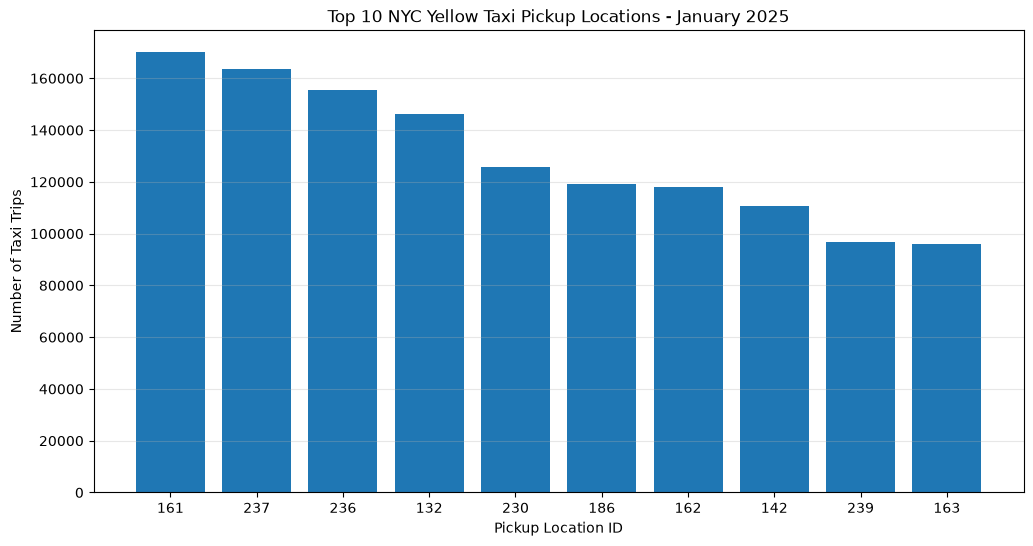

In [18]:
import matplotlib.pyplot as plt

zones_pd = top_pickup_zones.toPandas()

plt.figure(figsize=(12, 6))

plt.bar(
    zones_pd["PULocationID"].astype(str),
    zones_pd["count"]
)

plt.xlabel("Pickup Location ID")
plt.ylabel("Number of Taxi Trips")
plt.title("Top 10 NYC Yellow Taxi Pickup Locations - January 2025")

plt.grid(axis="y", alpha=0.3)
plt.show()

In [19]:
# Load the NYC Taxi Zone Lookup Table
zones = spark.read.csv(
    "taxi_zone_lookup.csv",
    header=True,
    inferSchema=True
)

zones.show(5)

+----------+-------------+--------------------+------------+
|LocationID|      Borough|                Zone|service_zone|
+----------+-------------+--------------------+------------+
|         1|          EWR|      Newark Airport|         EWR|
|         2|       Queens|         Jamaica Bay|   Boro Zone|
|         3|        Bronx|Allerton/Pelham G...|   Boro Zone|
|         4|    Manhattan|       Alphabet City| Yellow Zone|
|         5|Staten Island|       Arden Heights|   Boro Zone|
+----------+-------------+--------------------+------------+
only showing top 5 rows


In [20]:
#This will identify actual neighbourhoods/areas represented by top 10 location IDS
from pyspark.sql.functions import col

top_zones_named = (
    top_pickup_zones
    .join(
        zones,
        top_pickup_zones.PULocationID == zones.LocationID,
        "left"
    )
    .select(
        "PULocationID",
        "Borough",
        "Zone",
        "count"
    )
    .orderBy(col("count").desc())
)

top_zones_named.show(10, truncate=False)

+------------+---------+----------------------------+------+
|PULocationID|Borough  |Zone                        |count |
+------------+---------+----------------------------+------+
|161         |Manhattan|Midtown Center              |169977|
|237         |Manhattan|Upper East Side South       |163703|
|236         |Manhattan|Upper East Side North       |155647|
|132         |Queens   |JFK Airport                 |146137|
|230         |Manhattan|Times Sq/Theatre District   |125829|
|186         |Manhattan|Penn Station/Madison Sq West|119131|
|162         |Manhattan|Midtown East                |117930|
|142         |Manhattan|Lincoln Square East         |110585|
|239         |Manhattan|Upper West Side South       |96614 |
|163         |Manhattan|Midtown North               |95906 |
+------------+---------+----------------------------+------+



/home/evas-2026/spark_easter_2026/venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/evas-2026/spark_easter_2026/venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


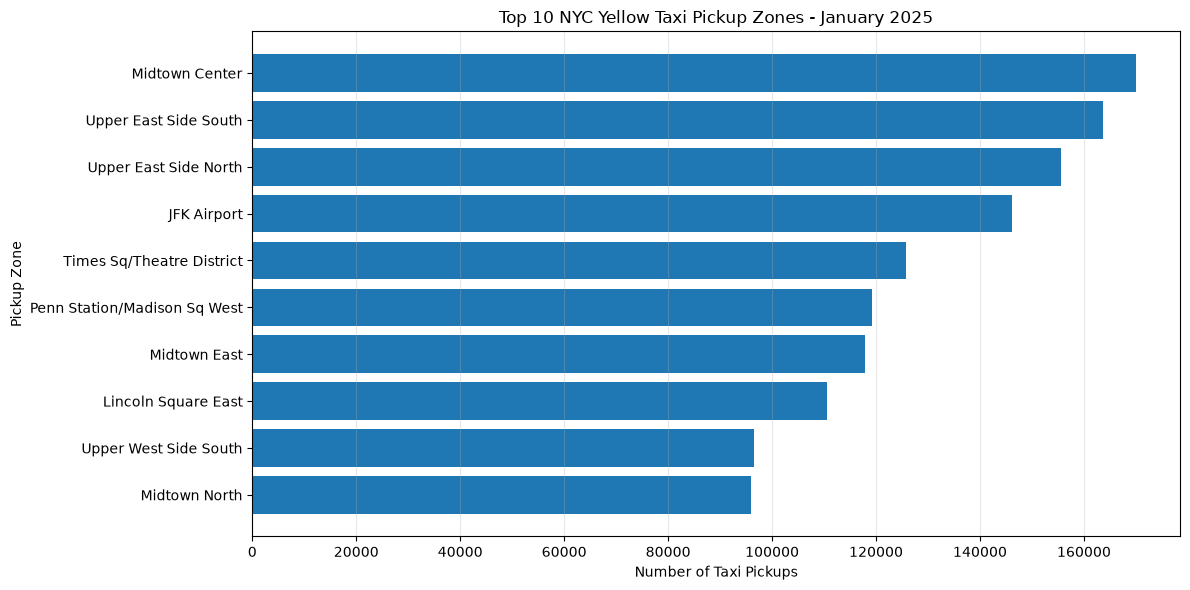

In [21]:
import matplotlib.pyplot as plt

zones_pd = top_zones_named.toPandas()

plt.figure(figsize=(12, 6))

plt.barh(
    zones_pd["Zone"],
    zones_pd["count"]
)

plt.xlabel("Number of Taxi Pickups")
plt.ylabel("Pickup Zone")
plt.title("Top 10 NYC Yellow Taxi Pickup Zones - January 2025")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
#Showing number of missing values in every column
from pyspark.sql.functions import col, sum as spark_sum

missing_values = df.select([
    spark_sum(col(c).isNull().cast("int")).alias(c)
    for c in df.columns
])

missing_values.show(truncate=False, vertical=True)

[Stage 55:=============================>                            (1 + 1) / 2]

-RECORD 0-----------------------
 VendorID              | 0      
 tpep_pickup_datetime  | 0      
 tpep_dropoff_datetime | 0      
 passenger_count       | 540149 
 trip_distance         | 0      
 RatecodeID            | 540149 
 store_and_fwd_flag    | 540149 
 PULocationID          | 0      
 DOLocationID          | 0      
 payment_type          | 0      
 fare_amount           | 0      
 extra                 | 0      
 mta_tax               | 0      
 tip_amount            | 0      
 tolls_amount          | 0      
 improvement_surcharge | 0      
 total_amount          | 0      
 congestion_surcharge  | 540149 
 Airport_fee           | 540149 
 cbd_congestion_fee    | 0      



In [67]:
from pyspark.sql.functions import col

affected_records = df.filter(
    col("passenger_count").isNull() &
    col("RatecodeID").isNull() &
    col("store_and_fwd_flag").isNull() &
    col("congestion_surcharge").isNull() &
    col("Airport_fee").isNull()
)

print("Records missing all five values:", affected_records.count())

Records missing all five values: 540149


In [23]:
from pyspark.sql.functions import col

# Create a cleaned DataFrame
df_clean = df.fillna({
    "passenger_count": -1,
    "RatecodeID": -1,
    "store_and_fwd_flag": "Unknown"
})

# Verify remaining missing values in these columns
df_clean.select(
    "passenger_count",
    "RatecodeID",
    "store_and_fwd_flag"
).show(10)

print("Missing values handled successfully!")

+---------------+----------+------------------+
|passenger_count|RatecodeID|store_and_fwd_flag|
+---------------+----------+------------------+
|              1|         1|                 N|
|              1|         1|                 N|
|              1|         1|                 N|
|              3|         1|                 N|
|              3|         1|                 N|
|              2|         1|                 N|
|              0|         1|                 N|
|              0|         1|                 N|
|              0|         1|                 N|
|              1|         1|                 N|
+---------------+----------+------------------+
only showing top 10 rows
Missing values handled successfully!


In [24]:
from pyspark.sql.functions import sum as spark_sum

df_clean.select([
    spark_sum(col(c).isNull().cast("int")).alias(c)
    for c in [
        "passenger_count",
        "RatecodeID",
        "store_and_fwd_flag"
    ]
]).show()

+---------------+----------+------------------+
|passenger_count|RatecodeID|store_and_fwd_flag|
+---------------+----------+------------------+
|              0|         0|                 0|
+---------------+----------+------------------+



In [25]:
from pyspark.sql.functions import col, unix_timestamp

# Calculate trip duration in minutes
df_clean = df_clean.withColumn(
    "trip_duration_minutes",
    (
        unix_timestamp("tpep_dropoff_datetime") -
        unix_timestamp("tpep_pickup_datetime")
    ) / 60
)

# Count records that fail each proposed rule
df_clean.selectExpr(
    "count(*) as total_records",
    "sum(case when trip_distance <= 0 or trip_distance > 100 then 1 else 0 end) as invalid_distance",
    "sum(case when fare_amount < 0 then 1 else 0 end) as negative_fares",
    "sum(case when trip_duration_minutes <= 0 or trip_duration_minutes > 240 then 1 else 0 end) as invalid_duration"
).show(truncate=False)

+-------------+----------------+--------------+----------------+
|total_records|invalid_distance|negative_fares|invalid_duration|
+-------------+----------------+--------------+----------------+
|3475226      |91055           |144118        |3329            |
+-------------+----------------+--------------+----------------+



In [26]:
from pyspark.sql.functions import col

df_valid = df_clean.filter(
    (col("trip_distance") > 0) &
    (col("trip_distance") <= 100) &
    (col("fare_amount") >= 0) &
    (col("trip_duration_minutes") > 0) &
    (col("trip_duration_minutes") <= 240)
)

print("Invalid trips filtered successfully!")

Invalid trips filtered successfully!


In [27]:
#Show records that remain after cleaning(remaining valid trips)
original_count = df.count()
valid_count = df_valid.count()

removed_count = original_count - valid_count

print("Original records:", original_count)
print("Valid records:", valid_count)
print("Removed records:", removed_count)

print(
    "Percentage removed:",
    round((removed_count / original_count) * 100, 2),
    "%"
)

[Stage 68:>                                                         (0 + 2) / 2]

Original records: 3475226
Valid records: 3251932
Removed records: 223294
Percentage removed: 6.43 %


In [28]:
#Feature Engineering
from pyspark.sql.functions import (
    col, hour, dayofmonth, dayofweek,
    month, when, date_format
)

df_features = (
    df_valid
    .withColumn(
        "pickup_hour",
        hour("tpep_pickup_datetime")
    )
    .withColumn(
        "pickup_day",
        dayofmonth("tpep_pickup_datetime")
    )
    .withColumn(
        "pickup_weekday",
        dayofweek("tpep_pickup_datetime")
    )
    .withColumn(
        "is_weekend",
        when(
            dayofweek("tpep_pickup_datetime").isin(1, 7),
            1
        ).otherwise(0)
    )
    .withColumn(
        "pickup_month",
        month("tpep_pickup_datetime")
    )
    .withColumn(
        "pickup_day_name",
        date_format("tpep_pickup_datetime", "EEEE")
    )
)

print("Feature engineering completed successfully!")

Feature engineering completed successfully!


In [29]:
df_features.select(
    "tpep_pickup_datetime",
    "pickup_hour",
    "pickup_day",
    "pickup_weekday",
    "is_weekend",
    "pickup_month",
    "pickup_day_name",
    "trip_duration_minutes"
).show(10, truncate=False)

+--------------------+-----------+----------+--------------+----------+------------+---------------+---------------------+
|tpep_pickup_datetime|pickup_hour|pickup_day|pickup_weekday|is_weekend|pickup_month|pickup_day_name|trip_duration_minutes|
+--------------------+-----------+----------+--------------+----------+------------+---------------+---------------------+
|2025-01-01 00:18:38 |0          |1         |4             |0         |1           |Wednesday      |8.35                 |
|2025-01-01 00:32:40 |0          |1         |4             |0         |1           |Wednesday      |2.55                 |
|2025-01-01 00:44:04 |0          |1         |4             |0         |1           |Wednesday      |1.95                 |
|2025-01-01 00:14:27 |0          |1         |4             |0         |1           |Wednesday      |5.566666666666666    |
|2025-01-01 00:21:34 |0          |1         |4             |0         |1           |Wednesday      |3.533333333333333    |
|2025-01-01 00:4

In [30]:
from pyspark.sql.functions import round as spark_round

df_features.select(
    "pickup_hour",
    "pickup_day",
    "pickup_weekday",
    "is_weekend",
    "pickup_month",
    "pickup_day_name",
    spark_round(
        "trip_duration_minutes", 2
    ).alias("trip_duration_minutes")
).show(10, truncate=False)

+-----------+----------+--------------+----------+------------+---------------+---------------------+
|pickup_hour|pickup_day|pickup_weekday|is_weekend|pickup_month|pickup_day_name|trip_duration_minutes|
+-----------+----------+--------------+----------+------------+---------------+---------------------+
|0          |1         |4             |0         |1           |Wednesday      |8.35                 |
|0          |1         |4             |0         |1           |Wednesday      |2.55                 |
|0          |1         |4             |0         |1           |Wednesday      |1.95                 |
|0          |1         |4             |0         |1           |Wednesday      |5.57                 |
|0          |1         |4             |0         |1           |Wednesday      |3.53                 |
|0          |1         |4             |0         |1           |Wednesday      |20.03                |
|0          |1         |4             |0         |1           |Wednesday      |1.4

In [31]:
#prep performance test
import time

# Select 100,000 records for performance testing
df_test = df_features.limit(100000)

print("Performance test dataset prepared!")

Performance test dataset prepared!


In [32]:
start_time = time.perf_counter()

df_test.groupBy("pickup_hour").count().collect()

without_cache = time.perf_counter() - start_time

print("Without caching:", round(without_cache, 3), "seconds")

Without caching: 0.809 seconds


In [33]:
# Cache the dataset
df_test.cache()

# Materialize the cache
df_test.count()

start_time = time.perf_counter()

df_test.groupBy("pickup_hour").count().collect()

with_cache = time.perf_counter() - start_time

print("With caching:", round(with_cache, 3), "seconds")

With caching: 0.267 seconds


In [34]:
#compare results
print("Without caching:", round(without_cache, 3), "seconds")
print("With caching:", round(with_cache, 3), "seconds")

if with_cache < without_cache:
    print("Caching improved performance.")
else:
    print("Caching did not improve performance in this test.")

# Release memory after the experiment
df_test.unpersist()

Without caching: 0.809 seconds
With caching: 0.267 seconds
Caching improved performance.


DataFrame[VendorID: int, tpep_pickup_datetime: timestamp_ntz, tpep_dropoff_datetime: timestamp_ntz, passenger_count: bigint, trip_distance: double, RatecodeID: bigint, store_and_fwd_flag: string, PULocationID: int, DOLocationID: int, payment_type: bigint, fare_amount: double, extra: double, mta_tax: double, tip_amount: double, tolls_amount: double, improvement_surcharge: double, total_amount: double, congestion_surcharge: double, Airport_fee: double, cbd_congestion_fee: double, trip_duration_minutes: double, pickup_hour: int, pickup_day: int, pickup_weekday: int, is_weekend: int, pickup_month: int, pickup_day_name: string]

In [35]:
# Check existing partitions
print("Original partitions:",
      df_features.rdd.getNumPartitions())

# Repartition into 4 partitions
df_repartitioned = df_features.repartition(4)

print("After repartition:",
      df_repartitioned.rdd.getNumPartitions())

# Reduce partitions to 2
df_coalesced = df_repartitioned.coalesce(2)

print("After coalesce:",
      df_coalesced.rdd.getNumPartitions())

Original partitions: 2


[Stage 82:=============================>                            (1 + 1) / 2]

After repartition: 4


[Stage 83:=============================>                            (1 + 1) / 2]

After coalesce: 2


In [36]:
print("Spark Version:", spark.version)
print("Cleaned Taxi Records:", df_features.count())

Spark Version: 4.2.0


[Stage 84:=============================>                            (1 + 1) / 2]

Cleaned Taxi Records: 3251932


In [37]:
# WEEK 3: SPARK SQL ANALYTICS

# Register cleaned data as a temporary SQL view
df_features.createOrReplaceTempView("trips")

print("Spark SQL view created successfully!")

Spark SQL view created successfully!


In [38]:
# Summary statistics using Spark SQL

result = spark.sql("""
    SELECT
        COUNT(*) AS total_trips,
        ROUND(AVG(trip_distance), 2) AS average_distance,
        ROUND(AVG(fare_amount), 2) AS average_fare,
        ROUND(AVG(trip_duration_minutes), 2) AS average_duration
    FROM trips
""")

result.show()

[Stage 87:>                                                         (0 + 2) / 2]

+-----------+----------------+------------+----------------+
|total_trips|average_distance|average_fare|average_duration|
+-----------+----------------+------------+----------------+
|    3251932|            3.17|       18.21|           14.68|
+-----------+----------------+------------+----------------+



In [39]:
# WEEK 3: Revenue Analysis by Hour

revenue_by_hour = spark.sql("""
    SELECT
        pickup_hour,
        COUNT(*) AS total_trips,
        ROUND(SUM(total_amount), 2) AS total_revenue,
        ROUND(AVG(total_amount), 2) AS average_revenue
    FROM trips
    GROUP BY pickup_hour
    ORDER BY pickup_hour
""")

revenue_by_hour.show(24)

[Stage 90:=============================>                            (1 + 1) / 2]

+-----------+-----------+-------------+---------------+
|pickup_hour|total_trips|total_revenue|average_revenue|
+-----------+-----------+-------------+---------------+
|          0|      86510|   2358494.51|          27.26|
|          1|      59500|   1495916.53|          25.14|
|          2|      40203|    967004.28|          24.05|
|          3|      25569|    638589.37|          24.98|
|          4|      17929|    550972.15|          30.73|
|          5|      20515|    711801.05|           34.7|
|          6|      46596|   1354473.93|          29.07|
|          7|      96732|   2581006.36|          26.68|
|          8|     133744|   3375147.44|          25.24|
|          9|     137151|   3477632.38|          25.36|
|         10|     142957|   3677612.71|          25.73|
|         11|     154302|   3926977.13|          25.45|
|         12|     168402|   5207817.29|          30.92|
|         13|     178434|   4720628.42|          26.46|
|         14|     193820|   5276009.54|         

/home/evas-2026/spark_easter_2026/venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/evas-2026/spark_easter_2026/venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
                                                                                

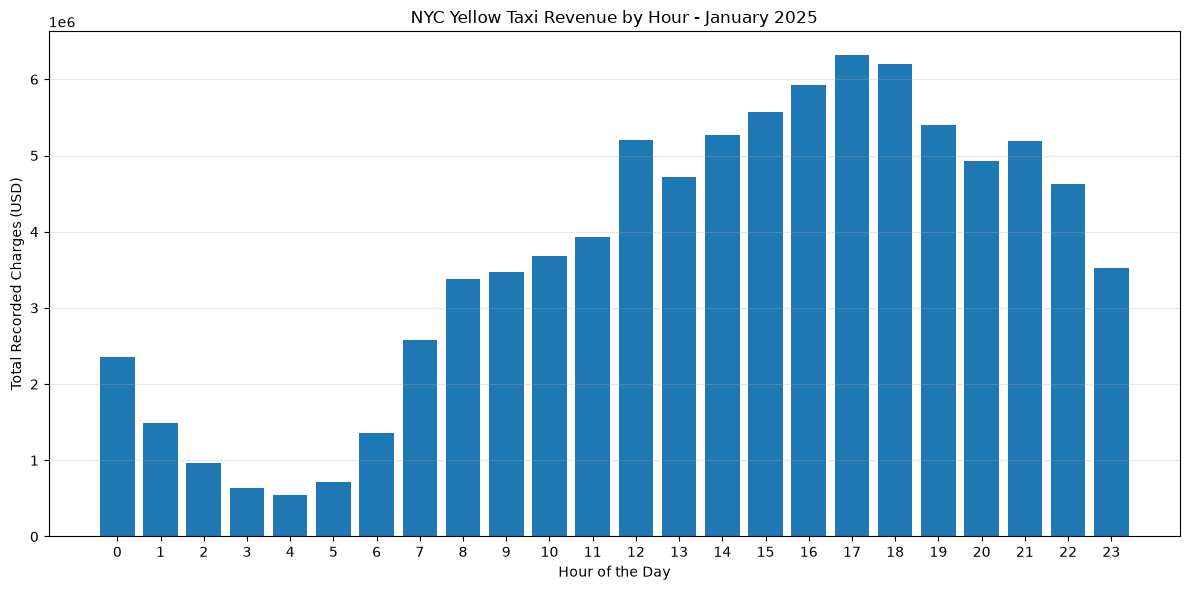

In [40]:
import matplotlib.pyplot as plt

# Convert only 24 aggregated records to Pandas
revenue_pd = revenue_by_hour.toPandas()

plt.figure(figsize=(12, 6))

plt.bar(
    revenue_pd["pickup_hour"],
    revenue_pd["total_revenue"]
)

plt.xlabel("Hour of the Day")
plt.ylabel("Total Recorded Charges (USD)")
plt.title("NYC Yellow Taxi Revenue by Hour - January 2025")

plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [41]:
# WEEK 3: SQL Window Functions

busiest_hours = spark.sql("""
    SELECT
        pickup_hour,
        total_trips,
        RANK() OVER (
            ORDER BY total_trips DESC
        ) AS hour_rank
    FROM (
        SELECT
            pickup_hour,
            COUNT(*) AS total_trips
        FROM trips
        GROUP BY pickup_hour
    ) hourly_summary
    ORDER BY hour_rank
""")

busiest_hours.show(24)

26/11/03 09:47:20 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/03 09:47:20 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/03 09:47:20 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/03 09:47:21 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/03 09:47:21 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/03 09:47:21 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/03 0

+-----------+-----------+---------+
|pickup_hour|total_trips|hour_rank|
+-----------+-----------+---------+
|         18|     236435|        1|
|         17|     229199|        2|
|         15|     204380|        3|
|         16|     202976|        4|
|         19|     200514|        5|
|         21|     194094|        6|
|         14|     193820|        7|
|         20|     184538|        8|
|         13|     178434|        9|
|         22|     170447|       10|
|         12|     168402|       11|
|         11|     154302|       12|
|         10|     142957|       13|
|          9|     137151|       14|
|          8|     133744|       15|
|         23|     126985|       16|
|          7|      96732|       17|
|          0|      86510|       18|
|          1|      59500|       19|
|          6|      46596|       20|
|          2|      40203|       21|
|          3|      25569|       22|
|          5|      20515|       23|
|          4|      17929|       24|
+-----------+-----------+---

In [42]:
from pyspark.sql.functions import col, count, rank
from pyspark.sql.window import Window

# Count trips for each pickup hour
hourly_counts = df_features.groupBy("pickup_hour").agg(
    count("*").alias("total_trips")
)

# Define ranking window
ranking_window = Window.orderBy(
    col("total_trips").desc()
)

# Rank busiest hours
busiest_hours_df = hourly_counts.withColumn(
    "hour_rank",
    rank().over(ranking_window)
).orderBy("hour_rank")

# Display results
busiest_hours_df.show(24)

26/11/03 09:47:21 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/03 09:47:21 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/03 09:47:21 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/03 09:47:22 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/03 09:47:22 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/03 09:47:22 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/03 0

+-----------+-----------+---------+
|pickup_hour|total_trips|hour_rank|
+-----------+-----------+---------+
|         18|     236435|        1|
|         17|     229199|        2|
|         15|     204380|        3|
|         16|     202976|        4|
|         19|     200514|        5|
|         21|     194094|        6|
|         14|     193820|        7|
|         20|     184538|        8|
|         13|     178434|        9|
|         22|     170447|       10|
|         12|     168402|       11|
|         11|     154302|       12|
|         10|     142957|       13|
|          9|     137151|       14|
|          8|     133744|       15|
|         23|     126985|       16|
|          7|      96732|       17|
|          0|      86510|       18|
|          1|      59500|       19|
|          6|      46596|       20|
|          2|      40203|       21|
|          3|      25569|       22|
|          5|      20515|       23|
|          4|      17929|       24|
+-----------+-----------+---

In [43]:
sql_results = busiest_hours.collect()
df_results = busiest_hours_df.collect()

sql_data = [
    (r.pickup_hour, r.total_trips, r.hour_rank)
    for r in sql_results
]

df_data = [
    (r.pickup_hour, r.total_trips, r.hour_rank)
    for r in df_results
]

print("SQL and DataFrame results match:",
      sql_data == df_data)

26/11/03 09:47:22 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/03 09:47:22 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/03 09:47:23 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/03 09:47:23 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/03 09:47:23 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/03 09:47:23 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/03 0

SQL and DataFrame results match: True


26/11/03 09:47:24 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/03 09:47:24 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/03 09:47:24 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/03 09:47:24 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


In [44]:
# WEEK 3: MACHINE LEARNING

from pyspark.sql.functions import col

# Select features and target variable
ml_data = df_features.select(
    "trip_distance",
    "pickup_hour",
    "pickup_weekday",
    "is_weekend",
    "PULocationID",
    "DOLocationID",
    "trip_duration_minutes"
).dropna()

# Take a reproducible sample for our 8 GB RAM computer
ml_sample = ml_data.sample(
    withReplacement=False,
    fraction=0.10,
    seed=42
)

print("Machine learning sample:", ml_sample.count())

ml_sample.show(5)

Machine learning sample: 324568
+-------------+-----------+--------------+----------+------------+------------+---------------------+
|trip_distance|pickup_hour|pickup_weekday|is_weekend|PULocationID|DOLocationID|trip_duration_minutes|
+-------------+-----------+--------------+----------+------------+------------+---------------------+
|          1.6|          0|             4|         0|         234|         148|                 12.4|
|          1.9|          0|             4|         0|         164|         229|   16.883333333333333|
|          1.2|          0|             4|         0|         246|          90|   17.033333333333335|
|         1.58|          0|             4|         0|         137|          79|   15.683333333333334|
|          1.4|          0|             4|         0|         229|         107|                 9.15|
+-------------+-----------+--------------+----------+------------+------------+---------------------+
only showing top 5 rows


In [45]:
# STEP 2: FEATURE ASSEMBLY

from pyspark.ml.feature import VectorAssembler

assembler = VectorAssembler(
    inputCols=[
        "trip_distance",
        "pickup_hour",
        "pickup_weekday",
        "is_weekend",
        "PULocationID",
        "DOLocationID"
    ],
    outputCol="features"
)

# Combine input features into a vector
ml_prepared = assembler.transform(ml_sample)

# Display assembled features and target
ml_prepared.select(
    "features",
    "trip_duration_minutes"
).show(10, truncate=False)

print("Feature assembly completed successfully!")

+------------------------------+---------------------+
|features                      |trip_duration_minutes|
+------------------------------+---------------------+
|[1.6,0.0,4.0,0.0,234.0,148.0] |12.4                 |
|[1.9,0.0,4.0,0.0,164.0,229.0] |16.883333333333333   |
|[1.2,0.0,4.0,0.0,246.0,90.0]  |17.033333333333335   |
|[1.58,0.0,4.0,0.0,137.0,79.0] |15.683333333333334   |
|[1.4,0.0,4.0,0.0,229.0,107.0] |9.15                 |
|[3.0,0.0,4.0,0.0,151.0,140.0] |16.816666666666666   |
|[3.46,0.0,4.0,0.0,237.0,249.0]|30.566666666666666   |
|[1.69,0.0,4.0,0.0,148.0,107.0]|11.466666666666667   |
|[1.36,0.0,4.0,0.0,238.0,236.0]|9.55                 |
|[10.42,0.0,4.0,0.0,90.0,243.0]|46.56666666666667    |
+------------------------------+---------------------+
only showing top 10 rows
Feature assembly completed successfully!


In [46]:
# STEP 3: TRAIN-TEST SPLIT

train_data, test_data = ml_prepared.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training records:", train_data.count())
print("Testing records:", test_data.count())

Training records: 259613


[Stage 133:============================>                            (1 + 1) / 2]

Testing records: 64955


In [47]:
# WEEK 3: RANDOM FOREST REGRESSION Training the RFR model

from pyspark.ml.regression import RandomForestRegressor

# Initialize Random Forest Regression
rf = RandomForestRegressor(
    featuresCol="features",
    labelCol="trip_duration_minutes",
    predictionCol="prediction",
    numTrees=20,
    maxDepth=5,
    seed=42
)

# Train the model
rf_model = rf.fit(train_data)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [48]:
# Generate predictions using testing data
predictions = rf_model.transform(test_data)

# Display actual and predicted trip durations
predictions.select(
    "trip_distance",
    "pickup_hour",
    "trip_duration_minutes",
    "prediction"
).show(10, truncate=False)

[Stage 150:>                                                        (0 + 1) / 1]

+-------------+-----------+---------------------+------------------+
|trip_distance|pickup_hour|trip_duration_minutes|prediction        |
+-------------+-----------+---------------------+------------------+
|0.01         |1          |0.6                  |7.7715749845826565|
|0.01         |1          |0.06666666666666667  |9.46763971796877  |
|0.01         |1          |1.7666666666666666   |8.574153122332092 |
|0.01         |3          |4.1                  |8.23770895660505  |
|0.01         |4          |2.8333333333333335   |14.329891300444146|
|0.01         |5          |0.08333333333333333  |8.026067630919748 |
|0.01         |6          |0.31666666666666665  |7.431632174657568 |
|0.01         |9          |0.13333333333333333  |10.072345954796013|
|0.01         |10         |0.13333333333333333  |8.864929521135377 |
|0.01         |10         |0.15                 |9.510304577816227 |
+-------------+-----------+---------------------+------------------+
only showing top 10 rows


In [49]:
from pyspark.ml.evaluation import RegressionEvaluator

# Calculate RMSE
rmse = RegressionEvaluator(
    labelCol="trip_duration_minutes",
    predictionCol="prediction",
    metricName="rmse"
).evaluate(predictions)

# Calculate MAE
mae = RegressionEvaluator(
    labelCol="trip_duration_minutes",
    predictionCol="prediction",
    metricName="mae"
).evaluate(predictions)

# Calculate R-squared
r2 = RegressionEvaluator(
    labelCol="trip_duration_minutes",
    predictionCol="prediction",
    metricName="r2"
).evaluate(predictions)

print("Random Forest Model Evaluation")
print("RMSE:", round(rmse, 2))
print("MAE:", round(mae, 2))
print("R²:", round(r2, 4))

[Stage 155:============================>                            (1 + 1) / 2]

Random Forest Model Evaluation
RMSE: 6.73
MAE: 4.28
R²: 0.6451


trip_distance : 0.7437
pickup_hour : 0.0187
pickup_weekday : 0.0034
is_weekend : 0.0035
PULocationID : 0.1909
DOLocationID : 0.0398


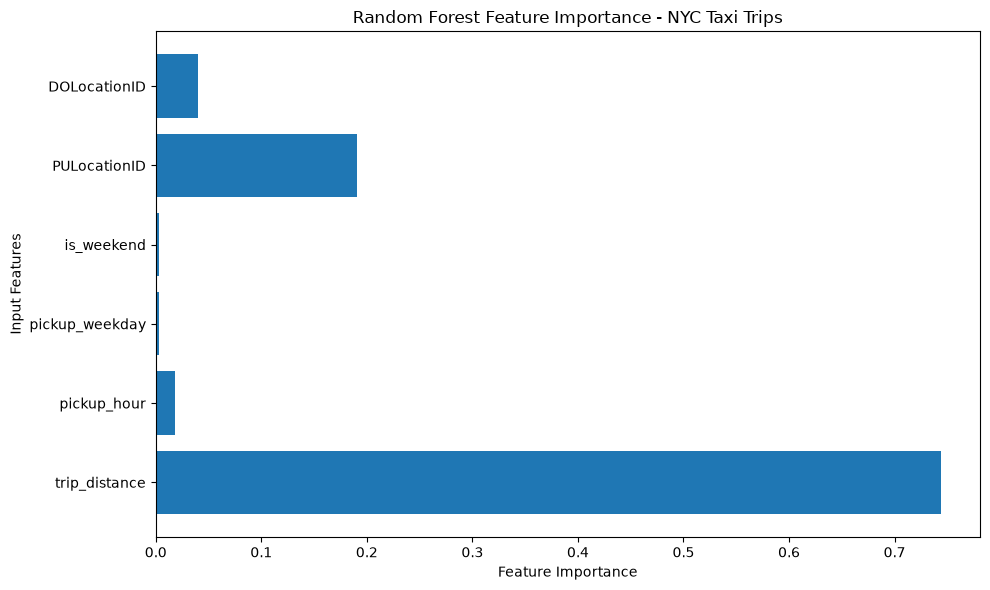

In [50]:
# STEP 7: RANDOM FOREST FEATURE IMPORTANCE

import matplotlib.pyplot as plt

# Input feature names
feature_names = [
    "trip_distance",
    "pickup_hour",
    "pickup_weekday",
    "is_weekend",
    "PULocationID",
    "DOLocationID"
]

# Extract feature importance
importance_values = rf_model.featureImportances.toArray()

# Display results
for name, importance in zip(feature_names, importance_values):
    print(name, ":", round(float(importance), 4))

# Create visualization
plt.figure(figsize=(10, 6))

plt.barh(feature_names, importance_values)

plt.xlabel("Feature Importance")
plt.ylabel("Input Features")
plt.title("Random Forest Feature Importance - NYC Taxi Trips")

plt.tight_layout()
plt.show()

In [51]:
# STEP 8: CHECK FOR OVERFITTING

from pyspark.ml.evaluation import RegressionEvaluator

# Generate predictions on training data
train_predictions = rf_model.transform(train_data)

# Create evaluator
evaluator = RegressionEvaluator(
    labelCol="trip_duration_minutes",
    predictionCol="prediction",
    metricName="rmse"
)

# Calculate training RMSE
train_rmse = evaluator.evaluate(train_predictions)

# Calculate testing RMSE
test_rmse = evaluator.evaluate(predictions)

print("RANDOM FOREST OVERFITTING ANALYSIS")
print("Training RMSE:", round(train_rmse, 2))
print("Testing RMSE:", round(test_rmse, 2))
print("RMSE Difference:", round(test_rmse - train_rmse, 2))

[Stage 159:============================>                            (1 + 1) / 2]

RANDOM FOREST OVERFITTING ANALYSIS
Training RMSE: 6.8
Testing RMSE: 6.73
RMSE Difference: -0.07


In [52]:
# STEP 9: SAVE TRAINED RANDOM FOREST MODEL

import os

model_path = os.path.abspath("models/nyc_taxi_random_forest")

rf_model.write().overwrite().save(model_path)

print("Random Forest model saved successfully!")
print("Model location:", model_path)

Random Forest model saved successfully!
Model location: /home/evas-2026/spark_easter_2026/models/nyc_taxi_random_forest


In [53]:
# STEP 10: SAVE CLEANED AND ENGINEERED DATASET

import os

data_path = os.path.abspath(
    "data/processed/nyc_taxi_january_2025"
)

df_features.write.mode("overwrite").parquet(data_path)

print("Processed dataset saved successfully!")
print("Dataset location:", data_path)

[Stage 168:============================>                            (1 + 1) / 2]

Processed dataset saved successfully!
Dataset location: /home/evas-2026/spark_easter_2026/data/processed/nyc_taxi_january_2025


In [54]:
# WEEK 4: STRUCTURED STREAMING

import os

# Create directories for streaming
os.makedirs("stream_folder", exist_ok=True)
os.makedirs("stream_output", exist_ok=True)
os.makedirs("stream_checkpoint", exist_ok=True)

print("Streaming folders created successfully!")

Streaming folders created successfully!


In [55]:
# Create a sample of 100 taxi records
stream_sample = df_features.limit(100)

# Save sample as CSV files
stream_sample.coalesce(1).write \
    .mode("overwrite") \
    .option("header", True) \
    .csv("stream_sample")

print("Streaming sample created successfully!")

Streaming sample created successfully!


In [56]:
# WEEK 4 - STEP 3: INITIALIZE STRUCTURED STREAMING

import os

# Define streaming input folder
stream_path = os.path.abspath("stream_folder")

# Use the schema from our cleaned dataset
stream_schema = df_features.schema

# Initialize streaming DataFrame
stream_df = spark.readStream \
    .schema(stream_schema) \
    .option("header", True) \
    .csv(stream_path)

print("Structured Streaming initialized successfully!")

print("Is Streaming:", stream_df.isStreaming)

Structured Streaming initialized successfully!
Is Streaming: True


In [57]:
# STEP 4: VERIFY STREAMING SCHEMA

stream_df.printSchema()

root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- cbd_congestion_fee: double (nullable = true)
 |-- trip_duration_minutes: double (nullable = true)
 |-- pickup_hour: integ

In [58]:
# WEEK 4 - STEP 5: SIMULATE INCOMING TAXI RECORDS

import os
import shutil
import glob

# Locate the sample CSV file
sample_files = glob.glob("stream_sample/part-*.csv")

if sample_files:
    source_file = sample_files[0]

    destination = os.path.join(
        "stream_folder",
        "taxi_batch_1.csv"
    )

    shutil.copy(source_file, destination)

    print("Taxi records successfully sent to streaming folder!")
    print("File:", destination)

else:
    print("No sample CSV file found!")

Taxi records successfully sent to streaming folder!
File: stream_folder/taxi_batch_1.csv


In [59]:
# WEEK 4 - STEP 6: PROCESS STREAMING DATA

from pyspark.sql.functions import count

# Aggregate incoming taxi records by pickup hour
stream_summary = stream_df.groupBy(
    "pickup_hour"
).agg(
    count("*").alias("total_trips")
)

# Start streaming query
query = stream_summary.writeStream \
    .outputMode("complete") \
    .format("memory") \
    .queryName("taxi_stream_results") \
    .option(
        "checkpointLocation",
        os.path.abspath("stream_checkpoint")
    ) \
    .trigger(availableNow=True) \
    .start()

# Wait for the available records to be processed
query.awaitTermination()

print("Streaming batch processed successfully!")

# Display results
spark.sql("""
    SELECT *
    FROM taxi_stream_results
    ORDER BY pickup_hour
""").show(24)

26/11/03 09:48:20 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.


Streaming batch processed successfully!
+-----------+-----------+
|pickup_hour|total_trips|
+-----------+-----------+
+-----------+-----------+



26/11/03 09:48:20 WARN MicroBatchExecution: Disabling AQE since AQE is not supported in stateful workloads.


In [60]:
# WEEK 4 - STEP 7: PREPARE SECOND STREAMING BATCH

from pyspark.sql.functions import col
import os

# Select 100 taxi trips from 6 PM (hour 18)
second_batch = df_features.filter(
    col("pickup_hour") == 18
).limit(100)

# Save the second batch separately
second_batch.coalesce(1).write \
    .mode("overwrite") \
    .option("header", True) \
    .csv("stream_sample_2")

print("Second streaming batch created successfully!")

second_batch.groupBy("pickup_hour").count().show()

Second streaming batch created successfully!
+-----------+-----+
|pickup_hour|count|
+-----------+-----+
|         18|  100|
+-----------+-----+



In [61]:
# WEEK 4 - STEP 8: SIMULATE NEW INCOMING DATA

import glob
import shutil
import os

# Locate the second CSV file
files = glob.glob("stream_sample_2/part-*.csv")

if files:
    source = files[0]

    destination = os.path.join(
        "stream_folder",
        "taxi_batch_2.csv"
    )

    shutil.copy(source, destination)

    print("Second batch successfully added!")
    print("Location:", destination)

else:
    print("Second batch CSV not found!")

Second batch successfully added!
Location: stream_folder/taxi_batch_2.csv


In [62]:
# WEEK 4 - STEP 9: PROCESS SECOND STREAMING BATCH

# Ensure the previous query has stopped
if query.isActive:
    query.stop()

# Resume using the existing checkpoint
query2 = stream_summary.writeStream \
    .outputMode("complete") \
    .format("memory") \
    .queryName("taxi_stream_results_2") \
    .option(
        "checkpointLocation",
        os.path.abspath("stream_checkpoint")
    ) \
    .trigger(availableNow=True) \
    .start()

query2.awaitTermination()

print("Second streaming batch processed successfully!")

spark.sql("""
    SELECT pickup_hour, total_trips
    FROM taxi_stream_results_2
    ORDER BY pickup_hour
""").show()

26/11/03 09:48:21 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.


Second streaming batch processed successfully!
+-----------+-----------+
|pickup_hour|total_trips|
+-----------+-----------+
+-----------+-----------+



26/11/03 09:48:21 WARN MicroBatchExecution: Disabling AQE since AQE is not supported in stateful workloads.


In [5]:
# Reinitialize Spark Session

from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("NYC Yellow Taxi Analysis") \
    .config("spark.sql.shuffle.partitions", "8") \
    .getOrCreate()

print("Spark session initialized successfully!")
print("Spark Version:", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/04 16:24:26 WARN Utils: Your hostname, DESKTOP-FJIT3EI, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/04 16:24:26 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/evas-2026/spark_easter_2026/venv/lib/python3.14/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/04 16:24:28 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark session initialized successfully!
Spark Version: 4.2.0


In [6]:
import os

data_path = os.path.abspath(
    "data/processed/nyc_taxi_january_2025"
)

df_features = spark.read.parquet(data_path)

stream_schema = df_features.schema

print("Processed dataset loaded successfully!")
print("Total records:", df_features.count())

df_features.show(5)

Processed dataset loaded successfully!
Total records: 3251932


26/11/04 16:24:54 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
                                                                                

+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+---------------------+-----------+----------+--------------+----------+------------+---------------+
|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|RatecodeID|store_and_fwd_flag|PULocationID|DOLocationID|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|Airport_fee|cbd_congestion_fee|trip_duration_minutes|pickup_hour|pickup_day|pickup_weekday|is_weekend|pickup_month|pickup_day_name|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+------------------

In [7]:
# WEEK 4 - STEP 9: PROCESS SECOND STREAMING BATCH

import os
import glob
import shutil

from pyspark.sql.functions import col, count

# 1. Create a separate folder for the second batch
os.makedirs("stream_folder_2", exist_ok=True)

# 2. Select 150 taxi records from 7 PM
second_batch = (
    df_features
    .filter(col("pickup_hour") == 19)
    .limit(150)
)

# 3. Save the selected records as CSV
second_batch.coalesce(1).write \
    .mode("overwrite") \
    .option("header", True) \
    .csv("stream_sample_2")

# 4. Copy the CSV file into the streaming input folder
second_files = glob.glob("stream_sample_2/part-*.csv")

if not second_files:
    raise FileNotFoundError("Second batch CSV file not found!")

shutil.copy(
    second_files[0],
    os.path.join("stream_folder_2", "taxi_batch_2.csv")
)

# 5. Initialize the second streaming DataFrame
stream_df_2 = spark.readStream \
    .schema(stream_schema) \
    .option("header", True) \
    .csv(os.path.abspath("stream_folder_2"))

# 6. Group records by pickup hour and count trips
stream_summary_2 = stream_df_2.groupBy("pickup_hour").agg(
    count("*").alias("total_trips")
)

# 7. Start the streaming query
query2 = stream_summary_2.writeStream \
    .outputMode("complete") \
    .format("memory") \
    .queryName("taxi_stream_results_2") \
    .option(
        "checkpointLocation",
        os.path.abspath("stream_checkpoint_2")
    ) \
    .trigger(availableNow=True) \
    .start()

# 8. Wait for streaming processing to finish
query2.awaitTermination()

# 9. Display the results
print("Second streaming batch processed successfully!")

spark.sql("""
    SELECT pickup_hour, total_trips
    FROM taxi_stream_results_2
    ORDER BY pickup_hour
""").show()

# 10. Verify the number of selected records
print("Records selected:", second_batch.count())

26/11/04 16:26:09 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
26/11/04 16:26:10 WARN MicroBatchExecution: Disabling AQE since AQE is not supported in stateful workloads.
                                                                                

Second streaming batch processed successfully!
+-----------+-----------+
|pickup_hour|total_trips|
+-----------+-----------+
|         19|        150|
+-----------+-----------+

Records selected: 150


In [8]:
# WEEK 4 - STEP 10: APPLY RANDOM FOREST MODEL TO STREAMING DATA

import os
import glob
import shutil

from pyspark.sql.functions import col
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressionModel

# 1. Define the six features used during model training
feature_cols = [
    "trip_distance",
    "pickup_hour",
    "pickup_weekday",
    "is_weekend",
    "PULocationID",
    "DOLocationID"
]

# 2. Load the previously trained Random Forest model
model_path = os.path.abspath(
    "models/nyc_taxi_random_forest"
)

rf_model_loaded = RandomForestRegressionModel.load(model_path)

print("Trained Random Forest model loaded successfully!")

# 3. Select 150 records from 7 PM
# Remove records missing any required model inputs
ml_stream_sample = (
    df_features
    .filter(col("pickup_hour") == 19)
    .dropna(subset=feature_cols)
    .limit(150)
)

# Verify selected records
selected_count = ml_stream_sample.count()

print("Records selected for prediction:", selected_count)

if selected_count == 0:
    raise ValueError("No suitable taxi records found!")

# 4. Prepare a clean streaming input folder
for folder in [
    "stream_ml_sample",
    "stream_ml_input",
    "stream_ml_checkpoint"
]:
    shutil.rmtree(folder, ignore_errors=True)

# 5. Save the selected records as CSV
ml_stream_sample.coalesce(1).write \
    .mode("overwrite") \
    .option("header", True) \
    .csv("stream_ml_sample")

# 6. Copy the CSV file into the streaming input folder
os.makedirs("stream_ml_input", exist_ok=True)

sample_files = glob.glob("stream_ml_sample/part-*.csv")

if not sample_files:
    raise FileNotFoundError("Streaming sample CSV not found!")

shutil.copy(
    sample_files[0],
    os.path.join("stream_ml_input", "taxi_ml_batch.csv")
)

# 7. Initialize the streaming DataFrame
stream_ml_df = spark.readStream \
    .schema(df_features.schema) \
    .option("header", True) \
    .csv(os.path.abspath("stream_ml_input"))

# 8. Assemble the model input features
assembler_ml = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features"
)

stream_ml_prepared = assembler_ml.transform(stream_ml_df)

# 9. Apply the trained Random Forest model
stream_predictions = rf_model_loaded.transform(
    stream_ml_prepared
)

# 10. Select actual and predicted trip durations
prediction_results = stream_predictions.select(
    "pickup_hour",
    "trip_distance",
    "trip_duration_minutes",
    "prediction"
)

# 11. Start the streaming prediction query
prediction_query = prediction_results.writeStream \
    .outputMode("append") \
    .format("memory") \
    .queryName("taxi_ml_predictions") \
    .option(
        "checkpointLocation",
        os.path.abspath("stream_ml_checkpoint")
    ) \
    .trigger(availableNow=True) \
    .start()

# 12. Wait for predictions to finish
prediction_query.awaitTermination()

# 13. Display the predictions
print("Streaming model predictions completed successfully!")

spark.sql("""
    SELECT
        pickup_hour,
        trip_distance,
        trip_duration_minutes AS actual_duration,
        prediction AS predicted_duration
    FROM taxi_ml_predictions
""").show(15, truncate=False)

# 14. Count the processed predictions
print(
    "Total predictions:",
    spark.sql(
        "SELECT COUNT(*) FROM taxi_ml_predictions"
    ).collect()[0][0]
)

Trained Random Forest model loaded successfully!
Records selected for prediction: 150


26/11/04 16:46:31 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.


Streaming model predictions completed successfully!
+-----------+-------------+------------------+------------------+
|pickup_hour|trip_distance|actual_duration   |predicted_duration|
+-----------+-------------+------------------+------------------+
|19         |0.98         |6.283333333333333 |9.568509581336375 |
|19         |0.9          |16.9              |9.750276030656188 |
|19         |5.71         |24.266666666666666|22.942089532879706|
|19         |1.2          |9.666666666666666 |11.2833669416915  |
|19         |5.0          |18.616666666666667|19.76293804045997 |
|19         |1.58         |10.066666666666666|10.725391110767195|
|19         |1.0          |14.566666666666666|9.84287172070761  |
|19         |2.2          |16.033333333333335|13.425179565091392|
|19         |1.2          |5.2               |10.419784559995904|
|19         |1.61         |6.483333333333333 |11.57394954762374 |
|19         |3.2          |18.416666666666668|17.195853160272183|
|19         |12.6       

In [9]:
# WEEK 4 - STEP 11: EVALUATE STREAMING MODEL PREDICTIONS

from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.sql.functions import col

# 1. Retrieve the actual and predicted durations
evaluation_data = spark.table("taxi_ml_predictions").select(
    col("trip_duration_minutes").cast("double").alias("actual_duration"),
    col("prediction").cast("double").alias("predicted_duration")
).dropna()

# 2. Count records available for evaluation
evaluation_count = evaluation_data.count()

print("Records evaluated:", evaluation_count)

if evaluation_count < 2:
    raise ValueError("Not enough valid records to evaluate the model!")

# 3. Calculate RMSE
rmse = RegressionEvaluator(
    labelCol="actual_duration",
    predictionCol="predicted_duration",
    metricName="rmse"
).evaluate(evaluation_data)

# 4. Calculate MAE
mae = RegressionEvaluator(
    labelCol="actual_duration",
    predictionCol="predicted_duration",
    metricName="mae"
).evaluate(evaluation_data)

# 5. Calculate R-squared
r2 = RegressionEvaluator(
    labelCol="actual_duration",
    predictionCol="predicted_duration",
    metricName="r2"
).evaluate(evaluation_data)

# 6. Display evaluation results
print("\nSTREAMING MODEL EVALUATION RESULTS")
print("----------------------------------")
print("RMSE:", round(rmse, 2), "minutes")
print("MAE:", round(mae, 2), "minutes")
print("R-squared:", round(r2, 4))

# 7. Compare with the original test results
print("\nCOMPARISON WITH ORIGINAL MODEL")
print("----------------------------------")
print("Original Test RMSE: 6.73 minutes")
print("Streaming RMSE:", round(rmse, 2), "minutes")

print("Original Test MAE: 4.28 minutes")
print("Streaming MAE:", round(mae, 2), "minutes")

print("Original Test R-squared: 0.6451")
print("Streaming R-squared:", round(r2, 4))

Records evaluated: 150



STREAMING MODEL EVALUATION RESULTS
----------------------------------
RMSE: 5.15 minutes
MAE: 4.13 minutes
R-squared: 0.6916

COMPARISON WITH ORIGINAL MODEL
----------------------------------
Original Test RMSE: 6.73 minutes
Streaming RMSE: 5.15 minutes
Original Test MAE: 4.28 minutes
Streaming MAE: 4.13 minutes
Original Test R-squared: 0.6451
Streaming R-squared: 0.6916
